# Creating `adata_subcell.h5ad` from raw spatial data

This notebook walks through turning raw Xenium (or MERFISH) instrument output into the
AnnData object that everything else in SubCellSpace consumes. It is the step *before*
[`example_usage_of_SubCellSpace_on_your_data.ipynb`](./example_usage_of_SubCellSpace_on_your_data.ipynb),
which picks up from the file produced here.

The processing itself is a config-driven pipeline — normally you write one YAML file and run
one command. This notebook does that, but stops between the steps to show what each one
produces, because the intermediate data is where most questions about the method live.

**What you end up with** is one AnnData object where each observation is a *cell* and each
variable is a *gene*, carrying:

| field | contents |
|---|---|
| `X` | transcript counts per (cell, gene) |
| `layers["subcell_embedding"]` | the 15-dimensional SubCellSpace embedding, shape `(n_cells, n_genes, 15)` |
| `layers["random_subcell_embedding"]` | the same, for a within-cell randomised control |
| `obsm["dapi_mask"]`, `obsm["cell_mask"]` | per-cell nucleus and cell masks, flattened 100x100 |
| `obsm["detected_transcripts"]` | every molecule per cell, with its within-cell coordinates |
| `obs` | `tile_nr`, `cell_id`, `global_row/col`, `cell_size`, ... |
| `var` | `gene_name`, `gene_label` |

**Two honest caveats before you start.** The stored outputs below come from a single
2000x2000 pixel tile cropped out of one sample, not a whole slide — that keeps the run to
about a minute so the notebook is actually executable. And running it needs Xenium output of
your own; there is no dataset bundled with this repository.

## 1. Prerequisites

Create the environment and run this notebook **from the repository root**:

```bash
conda env create -f yamls/pyxel_env_crossplatform.yml
conda activate pyxel_env
jupyter lab
```

Or use the prebuilt image, mounting the repo and your data:

```bash
docker run -it --rm -p 8888:8888 -v $(pwd):/workspace -v /path/to/data:/data \
    woutdavid/subcellspace:latest
```

A CUDA GPU makes segmentation and embedding much faster but is not required — the pipeline
detects what is available and falls back to CPU. On CPU expect this tile to take roughly
10-30 minutes instead of one.

In [1]:
# imports
import json
import shutil
import subprocess
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import anndata as ad
import awkward as ak
import matplotlib.pyplot as plt
from tifffile import TiffFile, imread, imwrite

# Same seed everywhere, so the randomised control layer is reproducible
seed = 101
np.random.seed(seed)

# anndata flags its awkward-array support as experimental on every read; silence that one
# so it does not repeat through the notebook. FutureWarning is filtered defensively only.
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*Awkward Arrays.*")

# SubCellSpace's own helpers live here; this notebook must be run from the repo root
sys.path.insert(0, "./make_paper_figures/src/")

%load_ext autoreload
%autoreload 2

## 2. Point this at your data

Two paths to set. `SAMPLE` is a raw Xenium output directory — the folder containing
`transcripts.parquet`, `experiment.xenium` and `morphology_focus/`. `WORK` is scratch space
for the small example tile we cut out of it.

If you want to process a **whole** sample rather than a tile, skip section 3 entirely and set
`BASEDIR = SAMPLE` in section 4.

In [2]:
import tempfile

# >>> CHANGE THIS to your own Xenium output directory <<<
SAMPLE = Path(
    "/mnt/data/syno_voet_backup/Xenium/20241213__134048__DavidWouters_4QDY8A_Repeat2/"
    "20241213__134048__DavidWouters_4QDY8A_Repeat2/"
    "output-XETG00075__0028935__Region_1__20241213__134115"
)

WORK = Path(tempfile.gettempdir()) / "subcellspace_demo_tile"

# Everything the pipeline needs from a Xenium run
for f in ["transcripts.parquet", "experiment.xenium", "morphology_focus"]:
    print(f"{'found  ' if (SAMPLE / f).exists() else 'MISSING'}  {f}")

PIXEL_SIZE = json.loads((SAMPLE / "experiment.xenium").read_text())["pixel_size"]
print(f"\npixel size: {PIXEL_SIZE} um/px")

found    transcripts.parquet
found    experiment.xenium
found    morphology_focus

pixel size: 0.2125 um/px


## 3. Cut out one example tile

A full Xenium slide is tens of gigabytes and takes hours. To keep this notebook runnable we
crop a 2000x2000 pixel window into a self-contained mini-`basedir` that the pipeline treats
exactly like a real sample.

Three things need care here, and each one fails *silently* if you get it wrong:

1. **Pick a window with tissue in it.** A window with no cells produces no per-tile count
   matrix, and the concatenation step then fails on an empty list. We find the densest window
   from `cells.parquet` (the instrument's own segmentation), which is small and fast to read.
2. **Re-origin the transcripts in microns, not pixels.** Coordinates are stored in microns and
   the pipeline divides by `pixel_size` to get pixels. Cropping moves the origin, so we
   subtract the crop origin *in microns*. Get this wrong and the molecules sit somewhere off
   the image while everything still appears to run.
3. **Keep every column.** The parser drops a fixed set of columns without tolerating their
   absence, so a trimmed table raises `KeyError`.

In [3]:
# Find the densest 2000x2000 window using the instrument's cell centroids
SIZE = 2000
cells = pd.read_parquet(SAMPLE / "cells.parquet")
row_px = cells["y_centroid"].to_numpy() / PIXEL_SIZE
col_px = cells["x_centroid"].to_numpy() / PIXEL_SIZE

row_edges = np.arange(0, row_px.max() + SIZE, SIZE)
col_edges = np.arange(0, col_px.max() + SIZE, SIZE)
counts, _, _ = np.histogram2d(row_px, col_px, bins=[row_edges, col_edges])
i, j = np.unravel_index(np.argmax(counts), counts.shape)
ROW0, COL0 = int(row_edges[i]), int(col_edges[j])

print(f"{len(cells):,} cells in the sample")
print(f"densest {SIZE}x{SIZE} window: row0={ROW0}, col0={COL0} ({int(counts[i, j])} cells)")

212,644 cells in the sample
densest 2000x2000 window: row0=46000, col0=28000 (757 cells)


In [4]:
# Crop the two stains the pipeline segments on: DAPI, and the intra-RNA channel.
# asarray(out="memmap") keeps us from pulling the whole 6 GB image into RAM.
(WORK / "images").mkdir(parents=True, exist_ok=True)

for name in ("dapi", "intra-rna"):
    src = SAMPLE / "images" / f"morphology_focus_0000_{name}.tif"
    with TiffFile(src) as tf:
        crop = tf.series[0].asarray(out="memmap")[ROW0:ROW0 + SIZE, COL0:COL0 + SIZE].copy()
    imwrite(WORK / "images" / f"morphology_focus_0000_{name}.tif", crop)
    print(f"{name:<10} {crop.shape} {crop.dtype}  intensity {crop.min()}-{crop.max()}")

dapi       (2000, 2000) uint16  intensity 28-11060
intra-rna  (2000, 2000) uint16  intensity 0-3424


If your sample has no `images/` directory yet, that is fine — the pipeline creates it by
splitting `morphology_focus/morphology_focus_0000.ome.tif` into its four channels
(DAPI, cell boundary, interior RNA, interior protein) the first time it runs. We read the
already-split files here only because cropping is simpler that way.

In [5]:
# Filter the transcripts to the window and re-origin them IN MICRONS.
import pyarrow.parquet as pq

x_lo, x_hi = COL0 * PIXEL_SIZE, (COL0 + SIZE) * PIXEL_SIZE
y_lo, y_hi = ROW0 * PIXEL_SIZE, (ROW0 + SIZE) * PIXEL_SIZE

pf = pq.ParquetFile(SAMPLE / "transcripts.parquet")
print(f"streaming {pf.metadata.num_rows:,} transcripts...")

chunks = []
for batch in pf.iter_batches(batch_size=2_000_000):
    df = batch.to_pandas()
    inside = (
        df.x_location.between(x_lo, x_hi, inclusive="left")
        & df.y_location.between(y_lo, y_hi, inclusive="left")
    )
    if inside.any():
        chunks.append(df.loc[inside])

sub = pd.concat(chunks, ignore_index=True)
sub["x_location"] -= x_lo          # <- the re-origin, in microns
sub["y_location"] -= y_lo
sub.to_parquet(WORK / "transcripts.parquet", index=False)

# experiment.xenium is copied unchanged: pixel_size does not depend on the crop
shutil.copy2(SAMPLE / "experiment.xenium", WORK / "experiment.xenium")

print(f"kept {len(sub):,} molecules over {sub.feature_name.nunique()} features")
print(f"basedir is {sum(f.stat().st_size for f in WORK.rglob('*') if f.is_file()) / 1e6:.0f} MB")

streaming 378,669,524 transcripts...
kept 1,174,726 molecules over 541 features
basedir is 32 MB


### Check the alignment before running anything

This is the one check worth never skipping. If the re-origin were wrong the pipeline would
still run to completion and produce a plausible-looking file full of misaligned data. Molecule
density should track the tissue: the empty patches in the density map should be the empty
patches in the DAPI image.

molecules inside the crop: 1.0000   (must be ~1.0)
corr(molecule density, DAPI): 0.703   (a misplaced crop gives ~0)


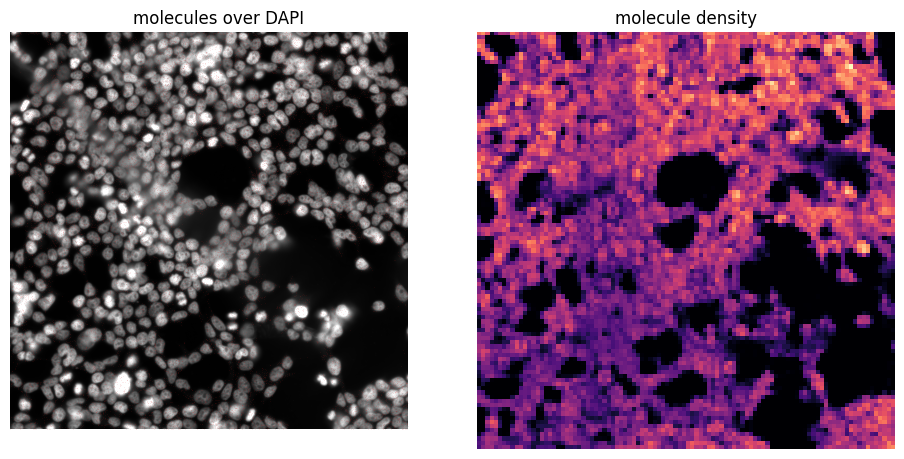

In [6]:
col = sub.x_location.to_numpy() / PIXEL_SIZE
row = sub.y_location.to_numpy() / PIXEL_SIZE
dapi = imread(WORK / "images" / "morphology_focus_0000_dapi.tif")

inside = ((row >= 0) & (row < SIZE) & (col >= 0) & (col < SIZE)).mean()
density, _, _ = np.histogram2d(row, col, bins=100, range=[[0, SIZE], [0, SIZE]])
binned = dapi.reshape(100, SIZE // 100, 100, SIZE // 100).mean(axis=(1, 3))
r = np.corrcoef(density.ravel(), binned.ravel())[0, 1]

print(f"molecules inside the crop: {inside:.4f}   (must be ~1.0)")
print(f"corr(molecule density, DAPI): {r:.3f}   (a misplaced crop gives ~0)")

fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.6))
axes[0].imshow(dapi, cmap="gray", vmax=np.percentile(dapi, 99))
pick = np.random.default_rng(seed).choice(len(row), 30_000, replace=False)
axes[0].scatter(col[pick], row[pick], s=0.1, c="tab:red", alpha=0.3, linewidths=0)
axes[0].set_title("molecules over DAPI")
axes[1].imshow(density, cmap="magma")
axes[1].set_title("molecule density")
for a in axes:
    a.axis("off")
plt.tight_layout()

## 4. Write the config

The pipeline is configured entirely from YAML — nothing in the Python needs editing. Only
`basedir` and `model_path` are required; every input path is derived from `basedir` unless you
override it. The annotated templates are in
[`raw_spatial_data_processing/configs/`](./raw_spatial_data_processing/configs/).

The settings that actually change your results:

| key | what it does |
|---|---|
| `platform` | `xenium` or `merfish`; selects the transcript parser and the expected file layout |
| `use_xenium_segmentation` | reuse the instrument's own masks (Xenium only). `false` re-segments with cellpose on DAPI + intra-RNA, which in our experience gives the best results |
| `keep_unmatched_nuclei` | keep nuclei with no matching cell boundary. We discard them — they tend to be segmentation artefacts |
| `expand_segmentation` | grow labels by N pixels, if the default boundaries look too tight |
| `spot_count_lower` / `_upper` | a (cell, gene) pair only gets an embedding if its molecule count falls in this window |
| `compute_random_control` | also build the within-cell randomised control layer, which the statistics downstream need |

The tile-specific settings below matter less scientifically but matter a lot for a small run:
`tile_size` must match the crop or the image gets zero-padded back up to the default 10000,
and the `n_jobs_*` defaults of 48 would fork 48 workers to process a single tile.

In [7]:
BASEDIR = WORK          # for a whole sample instead: BASEDIR = SAMPLE
MODEL = Path("./SubCellSpace").resolve()      # the trained model shipped in this repo

config = f'''
platform: xenium
basedir: {BASEDIR}
model_path: {MODEL}

use_xenium_segmentation: false   # cropped instrument masks would be out of register
keep_unmatched_nuclei: false
expand_segmentation: 0
seg_diameter: 100

tile_size: [{SIZE}, {SIZE}]      # match the crop so tile() does not zero-pad

n_jobs_count_matrix: 2           # one tile; the 48 default would fork 48 workers
n_jobs_single_cells: 2
n_jobs_count_spots: 2

keep_tiled_images: true          # keep intermediates so we can look at them below
compute_random_control: true
random_seed: 0
'''.lstrip()

CONFIG_PATH = WORK / "demo_tile.yaml"
CONFIG_PATH.write_text(config)
print(config)

platform: xenium
basedir: /tmp/subcellspace_demo_tile
model_path: /home/luna.kuleuven.be/u0147891/SubCellSpace/SubCellSpace

use_xenium_segmentation: false   # cropped instrument masks would be out of register
keep_unmatched_nuclei: false
expand_segmentation: 0
seg_diameter: 100

tile_size: [2000, 2000]      # match the crop so tile() does not zero-pad

n_jobs_count_matrix: 2           # one tile; the 48 default would fork 48 workers
n_jobs_single_cells: 2
n_jobs_count_spots: 2

keep_tiled_images: true          # keep intermediates so we can look at them below
compute_random_control: true
random_seed: 0



## 5. What is going to happen

Before running, ask the pipeline what it thinks needs doing. `--status` inspects the
checkpoints on disk and exits without touching anything — useful for confirming a config
points where you think it does.

In [8]:
def run_pipeline(*args):
    # Invoke the pipeline CLI and print its log
    cmd = [sys.executable, "-m", "raw_spatial_data_processing.run", str(CONFIG_PATH), *args]
    proc = subprocess.run(cmd, capture_output=True, text=True)
    print(proc.stdout or proc.stderr)
    return proc.returncode

run_pipeline("--status")

15:50:18 INFO Logging to subcellspace_demo_tile_log_24:08:26.log
15:50:18 INFO Pipeline steps (resuming at #1):
15:50:18 INFO   [NEXT]  1. parse_transcripts      Parse raw transcripts into pixel coordinates
15:50:18 INFO   [todo]  2. build_gene_map         Build the {gene_name: label} map from parsed transcripts
15:50:18 INFO   [todo]  3. build_tile_grid        Tile DAPI/cellbound/mask images and build the tile grid
15:50:18 INFO   [todo]  4. tile_transcripts       Split parsed transcripts into per-tile parquet files
15:50:18 INFO   [todo]  5. segment                Segment nuclei and cells per tile, measure them
15:50:18 INFO   [todo]  6. count_matrix           Build per-tile count matrices and concatenate them
15:50:18 INFO   [todo]  7. cut_single_cells       Cut each cell into a compact per-tile archive (+ optional diagnostic crops)
15:50:18 INFO   [todo]  8. count_spots            Count blobs on extra channels and fold into the count matrix
15:50:18 INFO   [todo]  9. build_adata   

0

Eleven steps, none of them done yet. Briefly, what each one is for:

| step | purpose |
|---|---|
| `parse_transcripts` | convert molecule coordinates from microns to image pixels |
| `build_gene_map` | assign each gene a stable integer label |
| `build_tile_grid` | cut the big images into tiles and record the geometry |
| `tile_transcripts` | split the molecule table per tile |
| `segment` | find nuclei and cells in each tile, then measure them |
| `count_matrix` | count molecules per (cell, gene) |
| `cut_single_cells` | crop every cell out into a compact per-tile archive |
| `count_spots` | count blobs on any extra image channels (skipped unless configured) |
| `build_adata` | assemble the count matrix and cell metadata into `adata.h5ad` |
| `coordinate_parse` | render each (cell, gene) as an image and embed it with the model |
| `finalize` | assemble everything into `adata_subcell.h5ad` |

Now run it. In production this single command is the whole story — everything after this
section is just looking at what it produced.

In [9]:
assert run_pipeline() == 0, "pipeline failed -- see the log above"

15:50:23 INFO Logging to subcellspace_demo_tile_log_24:08:26.log
15:50:23 INFO Pipeline steps (resuming at #1):
15:50:23 INFO   [NEXT]  1. parse_transcripts      Parse raw transcripts into pixel coordinates
15:50:23 INFO   [todo]  2. build_gene_map         Build the {gene_name: label} map from parsed transcripts
15:50:23 INFO   [todo]  3. build_tile_grid        Tile DAPI/cellbound/mask images and build the tile grid
15:50:23 INFO   [todo]  4. tile_transcripts       Split parsed transcripts into per-tile parquet files
15:50:23 INFO   [todo]  5. segment                Segment nuclei and cells per tile, measure them
15:50:23 INFO   [todo]  6. count_matrix           Build per-tile count matrices and concatenate them
15:50:23 INFO   [todo]  7. cut_single_cells       Cut each cell into a compact per-tile archive (+ optional diagnostic crops)
15:50:23 INFO   [todo]  8. count_spots            Count blobs on extra channels and fold into the count matrix
15:50:23 INFO   [todo]  9. build_adata   

Resuming is automatic: every step knows its own checkpoint, and the expensive steps check each
tile separately, so an interrupted run continues rather than starting over. Re-running the
command reports nothing left to do. `--from segment` forces a restart at a given step, and
`--force` redoes everything.

## 6. Looking at the intermediates

Everything lands under `<basedir>/parsed/`. The final file is the only one you need
afterwards, but the intermediates are worth understanding once — they are where you would look
if a run produced something odd.

In [10]:
PARSED = BASEDIR / "parsed"
for p in sorted(PARSED.rglob("*")):
    if p.is_file() and p.suffix in {".parquet", ".json", ".csv", ".h5ad", ".npz", ".pickle"}:
        rel = p.relative_to(PARSED)
        print(f"{p.stat().st_size / 1e6:9.2f} MB  {rel}")

     0.56 MB  adata.h5ad
    28.41 MB  adata_subcell.h5ad
     4.03 MB  coordinate_parsed/tile1_subcell.npz
    17.11 MB  coordinate_parsed/tile1_transcripts_zoomed.parquet
    16.87 MB  detected_transcripts_parsed.parquet
     0.01 MB  gene_map.json
     0.23 MB  single_cells/tile1_cells.npz
    17.32 MB  single_cells/tile1_transcripts.parquet
     0.61 MB  tiled/count_matrices/concat_count_matrix.csv
     0.61 MB  tiled/count_matrices/count_matrix_tile1.csv
    22.97 MB  tiled/detected_transcripts/detected_transcripts_transformed_tile1.parquet
     0.10 MB  tiled/measured_df/morphology_focus_0000_dapi_dapi-intra-rna_measured_tile1.csv
     0.00 MB  tiled/tile_grid.pickle


### Parsed molecules

`parse_transcripts` converts micron coordinates into image pixels: `row`/`col` are positions in
the full image, and `gene` is the feature name the rest of the pipeline keys off.

In [11]:
parsed = pd.read_parquet(PARSED / "detected_transcripts_parsed.parquet")
print(f"{len(parsed):,} molecules, {parsed.gene.nunique()} genes")
parsed[["gene", "row", "col"]].head()

1,174,726 molecules, 541 genes


,gene,row,col
0,AASS,594.044118,26.397059
1,AASS,498.529412,40.000000
2,AASS,105.220588,55.882353
3,AASS,616.397059,79.264706
4,AASS,346.470588,89.191176


### Segmentation

`segment` runs cellpose twice per tile — once on DAPI + intra-RNA for cell boundaries, once on
DAPI alone for nuclei — then matches each nucleus to the cell containing it. Nuclei without a
matching cell are dropped, since `keep_unmatched_nuclei` is `false`.

cellpose found 608 cells and 552 nuclei; 515 survived matching
median cell area 2669 px (~58 px across)


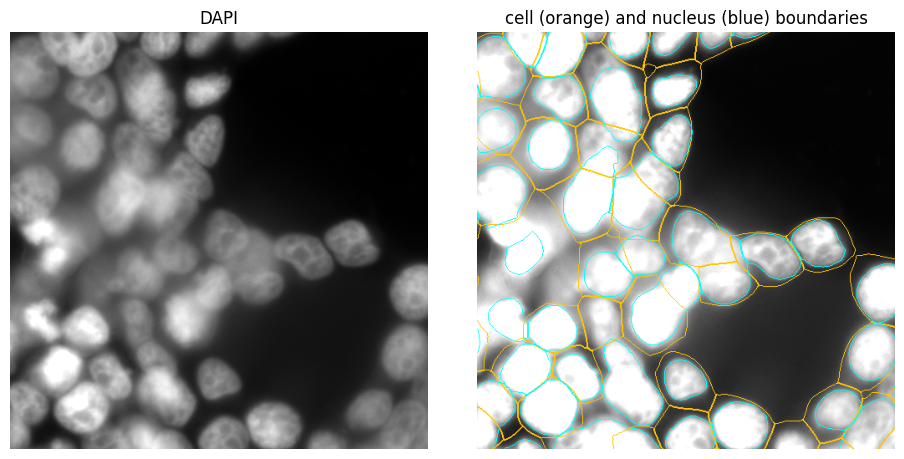

In [12]:
from skimage.segmentation import find_boundaries

tile_nr = 1
dapi_tile = imread(next((PARSED / "tiled" / "dapi_tiles").glob("*tile1.tif")))
cells_lab = imread(next((PARSED / "tiled" / "labeled_cellbound").glob("*tile1.tif")))
nuc_lab = imread(next((PARSED / "tiled" / "labeled_dapi").glob("*tile1.tif")))
measured = pd.read_csv(next((PARSED / "tiled" / "measured_df").glob("*tile1.csv")))

print(f"cellpose found {cells_lab.max()} cells and {nuc_lab.max()} nuclei; "
      f"{len(measured)} survived matching")
print(f"median cell area {measured.Area.median():.0f} px "
      f"(~{2 * np.sqrt(measured.Area.median() / np.pi):.0f} px across)")

zoom = np.s_[600:1100, 600:1100]
overlay = np.stack([dapi_tile[zoom] / dapi_tile[zoom].max()] * 3, axis=-1)
overlay[find_boundaries(cells_lab[zoom], mode="outer")] = [1.0, 0.35, 0.0]
overlay[find_boundaries(nuc_lab[zoom], mode="outer")] = [0.0, 0.7, 1.0]

fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.6))
axes[0].imshow(dapi_tile[zoom], cmap="gray", vmax=np.percentile(dapi_tile, 99))
axes[0].set_title("DAPI")
axes[1].imshow(np.clip(overlay * 2.2, 0, 1))
axes[1].set_title("cell (orange) and nucleus (blue) boundaries")
for a in axes:
    a.axis("off")
plt.tight_layout()

### Counts, and the per-cell archive

`count_matrix` assigns molecules to cells and counts them. `cut_single_cells` then crops each
cell out — its masks and its molecules — into one compressed `.npz` per tile rather than
millions of small files, which is what makes a whole-slide run practical.

In [13]:
counts = pd.read_csv(PARSED / "tiled" / "count_matrices" / "concat_count_matrix.csv", index_col=0)
print(f"count matrix: {counts.shape[0]} cells x {counts.shape[1]} genes")
print(f"median molecules per cell: {counts.sum(axis=1).median():.0f}")

archive = np.load(next((PARSED / "single_cells").glob("*_cells.npz")), allow_pickle=True)
print(f"\nper-tile archive keys: {list(archive.keys())}")
print(f"cells stored: {len(archive['cell_ids'])}")
print(f"one cell's dapi crop: {archive['dapi'][0].shape}")

count matrix: 515 cells x 541 genes
median molecules per cell: 1721

per-tile archive keys: ['cell_ids', 'dapi', 'cell']
cells stored: 463
one cell's dapi crop: (91, 76)


## 7. The result

`adata_subcell.h5ad` is the file everything downstream uses.

In [14]:
adata = ad.read_h5ad(PARSED / "adata_subcell.h5ad")
adata

AnnData object with n_obs × n_vars = 515 × 541
    obs: 'name', 'tile_nr', 'local_row', 'local_col', 'cell_id', 'global_row', 'global_col', 'cell_size'
    var: 'gene_name', 'gene_label'
    uns: 'measured_df'
    obsm: 'cell_mask', 'dapi_mask', 'detected_transcripts'
    layers: 'random_subcell_embedding', 'subcell_embedding'

In [15]:
emb = adata.layers["subcell_embedding"]
filled = int(emb.reshape(-1, emb.shape[-1]).any(axis=1).sum())
print(f"{adata.n_obs} cells x {adata.n_vars} genes, embedding dimension {emb.shape[-1]}")
print(f"{filled:,} of {adata.n_obs * adata.n_vars:,} (cell, gene) pairs carry an embedding")
print("\nA pair is embedded only when its molecule count falls inside "
      "[spot_count_lower, spot_count_upper]; everything else stays a zero vector, "
      "which is how downstream code recognises 'no measurement here'.")

515 cells x 541 genes, embedding dimension 15
22,200 of 278,615 (cell, gene) pairs carry an embedding

A pair is embedded only when its molecule count falls inside [spot_count_lower, spot_count_upper]; everything else stays a zero vector, which is how downstream code recognises 'no measurement here'.


Two things about this object are easy to trip over.

**Cells at the tile edge have no embedding.** Cells touching a tile boundary are skipped when
cells are cut out, because they are only partly inside the tile. They still appear in the count
matrix, with zero-vector embeddings and empty masks. On a whole slide that is a small fraction
of the edge cells of each tile; on a single-tile crop like this one it is the border of the
crop, so proportionally more.

**Embeddings are indexed `[cell, gene, :]`.** The layer is dense and three-dimensional, not the
two-dimensional matrix AnnData layers usually are.

cell tile1_row309_col408_104_corrID_108, gene XIST: 100 molecules (inside the [spot_count_lower, spot_count_upper] window, so it has an embedding)


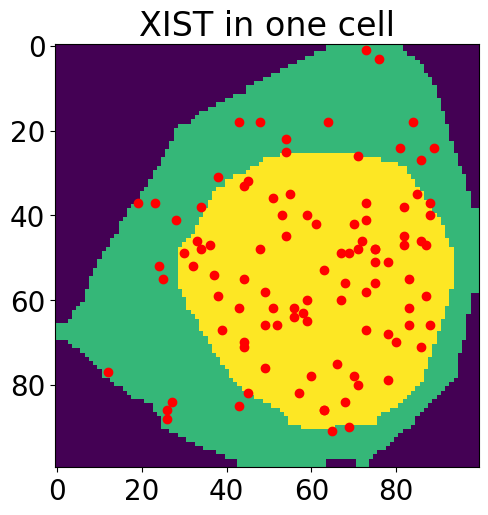

In [16]:
# One observation, end to end: masks, molecules, and its embedding
from plotting import plotFullDataPoint

counts_per_pair = np.asarray(adata.X)
has_embedding = adata.layers["subcell_embedding"].any(axis=-1)

# Pick the busiest pair that actually carries an embedding. Deliberately NOT the busiest
# pair overall: anything above spot_count_upper is left un-embedded on purpose, so an
# argmax over the counts alone would hand back a zero vector every time.
ranked = np.where(has_embedding, counts_per_pair, -1)
cell_i, gene_j = np.unravel_index(np.argmax(ranked), ranked.shape)

cell_id = adata.obs["cell_id"].iloc[cell_i]
gene = adata.var_names[gene_j]
tile_nr = int(adata.obs["tile_nr"].iloc[cell_i])
print(f"cell {cell_id}, gene {gene}: {int(counts_per_pair[cell_i, gene_j])} molecules "
      f"(inside the [spot_count_lower, spot_count_upper] window, so it has an embedding)")

plt.rcParams["figure.figsize"] = [5.5, 5.5]
plotFullDataPoint(adata, tile_nr=tile_nr, cell_id=cell_id, gene=gene)
plt.title(f"{gene} in one cell")
plt.show()

The background is the cell mask with the nucleus on top; the dots are the individual molecules
of that gene, placed in the cell's own 100x100 frame. That image is exactly what the model
sees, and its 15-dimensional summary is the embedding:

In [17]:
vector = adata.layers["subcell_embedding"][cell_i, gene_j]
control = adata.layers["random_subcell_embedding"][cell_i, gene_j]
print("embedding:      ", np.array2string(vector, precision=2, suppress_small=True))
print("random control: ", np.array2string(control, precision=2, suppress_small=True))

embedding:       [  6.69   3.26   1.52   6.06   7.21  -2.6   13.    -1.57  -3.67  -0.73
   2.27  -2.52  -6.35 -13.24  -5.02]
random control:  [ 8.01  1.98 -4.04  0.62 12.61 -3.37  6.57  1.97 -4.58 -0.31  0.63  1.77
 -0.75 -4.41 -3.29]


The control is the same cell and the same number of molecules, scattered at random inside the
cell mask. Comparing a gene's real embeddings against its controls is how the downstream
analysis decides whether a localisation pattern is real rather than a consequence of cell shape
or molecule count.

## 8. Handing off to the analysis notebook

The analysis code works on a *flattened* view, where each row is one (cell, gene) observation
rather than one cell. `reshape_and_filter_anndata_with_index_and_mapping` does that conversion
and drops the zero-vector pairs.

In [18]:
from adata_utils import reshape_and_filter_anndata_with_index_and_mapping

flat = reshape_and_filter_anndata_with_index_and_mapping(adata)
print(f"{adata.n_obs} cells x {adata.n_vars} genes  ->  {flat.n_obs:,} observations "
      f"x {flat.n_vars} latent dimensions")
flat.obs[["cell_id", "original_gene_name", "n_spots", "n_spots_interval"]].head()

515 cells x 541 genes  ->  22,200 observations x 15 latent dimensions


,cell_id,original_gene_name,n_spots,n_spots_interval
tile1_row52_col361_15_corrID_16_FOXG1,tile1_row52_col361_15_corrID_16,FOXG1,26,20-30
tile1_row52_col361_15_corrID_16_RTN3,tile1_row52_col361_15_corrID_16,RTN3,11,10-20
tile1_row52_col361_15_corrID_16_ALDH18A1,tile1_row52_col361_15_corrID_16,ALDH18A1,27,20-30
tile1_row52_col361_15_corrID_16_SNX5,tile1_row52_col361_15_corrID_16,SNX5,13,10-20
tile1_row52_col361_15_corrID_16_SLC30A9,tile1_row52_col361_15_corrID_16,SLC30A9,15,10-20


That is the object [`example_usage_of_SubCellSpace_on_your_data.ipynb`](./example_usage_of_SubCellSpace_on_your_data.ipynb)
starts from. Point its `base_dir` at `<basedir>/parsed/` and continue there: classifying genes
for pattern presence, assigning pattern subtypes, and unsupervised exploration of the latent
space.

## 9. Running this on a whole sample

Set `BASEDIR = SAMPLE`, drop the `tile_size` override, and raise the `n_jobs_*` values to
something suited to your machine. For scale, a full slide of this panel — 36 tiles,
around 400 million molecules — took **4h50m** on one A40:

| step | time |
|---|---|
| `parse_transcripts` | 6m |
| `tile_transcripts` | 25m |
| `segment` | 1h14m |
| `count_matrix` | 5m |
| `cut_single_cells` | 3m |
| `build_adata` | 1m |
| `coordinate_parse` | 2h05m |
| `finalize` | 50m |

`segment` and `coordinate_parse` are deliberately sequential, because cellpose and the encoder
each want the whole GPU. `compute_random_control` roughly doubles `coordinate_parse`, and
`finalize` is the memory high-water mark — it allocates two dense
`(n_cells, n_genes, 15)` float32 arrays, about 10 GB at this scale.

### If something goes wrong

- **`FileNotFoundError` about cellbound tiles.** The pipeline segments on DAPI plus a second
  stain, and could not find the second one. Set `cellbound2_path` to whichever membrane,
  interior-RNA or PolyT image your run has.
- **A `ValueError` about the morphology image having no channel axis.** Older Xenium runs ship a
  single-channel DAPI morphology image, so there is no second stain to derive. Set `dapi_path`
  and `cellbound2_path` explicitly.
- **An empty-concatenation error at `count_matrix`.** No cells were segmented in some tile.
  On a crop this usually means the window missed the tissue.
- **Disk.** Intermediates are much smaller than they used to be, but a whole slide still writes
  tens of gigabytes. `keep_tiled_images: false` (the default) deletes the regenerable image
  tiles when the run finishes.

### MERFISH

Everything above applies, with `platform: merfish`, `use_xenium_segmentation: false`, and the
MERSCOPE file layout (`detected_transcripts.csv`, `images/micron_to_mosaic_pixel_transform.csv`,
`mosaic_DAPI_z3.tif`). If your run has `Cellbound3` it is folded into the boundary channel
automatically; if it has PolyT instead of Cellbound stains, point `cellbound2_path` at that.
See [`configs/example_merfish.yaml`](./raw_spatial_data_processing/configs/example_merfish.yaml).